## AQI Prediction for Indian Cities: Preprocessing and Feature Engineering

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("Data/city_day.csv", parse_dates=["Date"])
df = df.sort_values(["City", "Date"]).reset_index(drop=True)
print(df.shape)

(29531, 16)


**Insight:** The dataset has 29,531 rows and 16 columns, with one row per city per day, so the data is sorted by city and date before the next-day shift.

## 2. Preprocessing

In [2]:
df["AQI_tomorrow"] = df.groupby("City")["AQI"].shift(-1)
df["next_date"] = df.groupby("City")["Date"].shift(-1)
df.loc[(df["next_date"] - df["Date"]).dt.days != 1, "AQI_tomorrow"] = np.nan

print(df[["City", "Date", "AQI", "AQI_tomorrow"]].head(10))
print("Rows with a valid tomorrow target:", df["AQI_tomorrow"].notna().sum())

        City       Date  AQI  AQI_tomorrow
0  Ahmedabad 2015-01-01  NaN           NaN
1  Ahmedabad 2015-01-02  NaN           NaN
2  Ahmedabad 2015-01-03  NaN           NaN
3  Ahmedabad 2015-01-04  NaN           NaN
4  Ahmedabad 2015-01-05  NaN           NaN
5  Ahmedabad 2015-01-06  NaN           NaN
6  Ahmedabad 2015-01-07  NaN           NaN
7  Ahmedabad 2015-01-08  NaN           NaN
8  Ahmedabad 2015-01-09  NaN           NaN
9  Ahmedabad 2015-01-10  NaN           NaN
Rows with a valid tomorrow target: 24849


### 2.1 Creating tomorrow's AQI as the target

In [3]:
df["AQI_tomorrow"] = df.groupby("City")["AQI"].shift(-1)
df["next_date"] = df.groupby("City")["Date"].shift(-1)
df.loc[(df["next_date"] - df["Date"]).dt.days != 1, "AQI_tomorrow"] = np.nan

print(df[["City", "Date", "AQI", "AQI_tomorrow"]].head(10))
print("Rows with a valid tomorrow target:", df["AQI_tomorrow"].notna().sum())

        City       Date  AQI  AQI_tomorrow
0  Ahmedabad 2015-01-01  NaN           NaN
1  Ahmedabad 2015-01-02  NaN           NaN
2  Ahmedabad 2015-01-03  NaN           NaN
3  Ahmedabad 2015-01-04  NaN           NaN
4  Ahmedabad 2015-01-05  NaN           NaN
5  Ahmedabad 2015-01-06  NaN           NaN
6  Ahmedabad 2015-01-07  NaN           NaN
7  Ahmedabad 2015-01-08  NaN           NaN
8  Ahmedabad 2015-01-09  NaN           NaN
9  Ahmedabad 2015-01-10  NaN           NaN
Rows with a valid tomorrow target: 24849


**Insight:** Only 24,849 rows have a valid tomorrow target. The rest are either the last day of each city's record or are followed by a gap, so they are dropped before training.

### 2.2 Removing copied-CO rows and capping AQI at 500

In [4]:
# Drop the Ahmedabad rows where NO equals CO (copied CO column)
copied = (df["City"] == "Ahmedabad") & (df["NO"] == df["CO"])
print("Rows dropped (copied CO):", copied.sum())
df = df[~copied].copy()

# Cap AQI at the official scale maximum of 500
df["AQI"] = df["AQI"].clip(upper=500)
df["AQI_tomorrow"] = df["AQI_tomorrow"].clip(upper=500)

print(df.shape)
print(df["AQI"].describe())

Rows dropped (copied CO): 1317
(28214, 18)
count    23604.000000
mean       149.720979
std        100.686049
min         13.000000
25%         79.000000
50%        113.000000
75%        187.000000
max        500.000000
Name: AQI, dtype: float64


**Insight:** Dropping 1,317 copied-CO rows left 28,214 rows. Capping AQI at 500 brings the maximum down to 500 and lowers the mean from about 166 to 150, so the extreme Ahmedabad values no longer distort the target.

### 2.3 Splitting into train and test by date

In [5]:
# Drop rows with no target, then split by date (no random shuffling)
model_df = df.dropna(subset=["AQI_tomorrow"]).copy()

cutoff = pd.Timestamp("2019-01-01")
train = model_df[model_df["Date"] < cutoff]
test = model_df[model_df["Date"] >= cutoff]

print("Train rows:", len(train), "| Test rows:", len(test))
print("Train dates:", train["Date"].min().date(), "to", train["Date"].max().date())
print("Test dates:", test["Date"].min().date(), "to", test["Date"].max().date())

Train rows: 12575 | Test rows: 11027
Train dates: 2015-01-01 to 2018-12-31
Test dates: 2019-01-01 to 2020-06-30


**Insight:** The split is by date, not random. A random split would let the model train on future days and test on past ones, which leaks information. Training on 2015 to 2018 and testing on 2019 to 2020 mimics real forecasting, where you only know the past.

### 2.4 Filling missing pollutant values using training data only

In [6]:
features = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "NH3"]

# Learn the fill values from the training set only
fill_values = train[features].median()
print(fill_values)

# Apply the same values to train and test
train = train.copy()
test = test.copy()
train[features] = train[features].fillna(fill_values)
test[features] = test[features].fillna(fill_values)

print("Missing after filling (train):", train[features].isna().sum().sum())
print("Missing after filling (test):", test[features].isna().sum().sum())

PM2.5     57.150
PM10     108.635
NO2       24.975
SO2        7.970
CO         0.970
O3        31.210
NH3       21.180
dtype: float64
Missing after filling (train): 0
Missing after filling (test): 0


**Insight:** The fill values are medians learned from the training set only, then applied to both train and test. The median resists extreme spikes, and using training data only prevents the test set from leaking into training.

### 2.5 Adding date features (month, day of week, season)

In [7]:
def add_date_features(d):
    d = d.copy()
    d["month"] = d["Date"].dt.month
    d["day_of_week"] = d["Date"].dt.dayofweek
    d["season"] = d["month"].map({
        12: "winter", 1: "winter", 2: "winter",
        3: "summer", 4: "summer", 5: "summer",
        6: "monsoon", 7: "monsoon", 8: "monsoon", 9: "monsoon",
        10: "post_monsoon", 11: "post_monsoon",
    })
    return d

train = add_date_features(train)
test = add_date_features(test)

print(train[["Date", "month", "day_of_week", "season"]].head())
print(test["season"].value_counts())

           Date  month  day_of_week        season
1013 2017-10-10     10            1  post_monsoon
1023 2017-10-20     10            4  post_monsoon
1024 2017-10-21     10            5  post_monsoon
1025 2017-10-22     10            6  post_monsoon
1026 2017-10-23     10            0  post_monsoon
season
summer          3803
winter          3023
monsoon         2941
post_monsoon    1260
Name: count, dtype: int64


**Insight:** Air quality follows the calendar. Winter smog and the monsoon's cleaning effect are seasonal, and weekday traffic differs from weekends, so month, season and day of week let the model learn these patterns.

### 2.6 Selecting the final features and target

In [8]:
# One-hot encode season (text to numbers), fitted on column names only
train = pd.get_dummies(train, columns=["season"], dtype=int)
test = pd.get_dummies(test, columns=["season"], dtype=int)

season_cols = [c for c in train.columns if c.startswith("season_")]
test = test.reindex(columns=train.columns, fill_value=0)

feature_cols = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "NH3", "month", "day_of_week"] + season_cols

X_train, y_train = train[feature_cols], train["AQI_tomorrow"]
X_test, y_test = test[feature_cols], test["AQI_tomorrow"]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Features:", feature_cols)

X_train: (12575, 13) | X_test: (11027, 13)
Features: ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'NH3', 'month', 'day_of_week', 'season_monsoon', 'season_post_monsoon', 'season_summer', 'season_winter']


**Insight:** The model uses 13 features: seven pollutant readings, month, day of week and four one-hot season columns. Season is text, so it is converted to 0/1 columns. The helper column next_date is left out so it cannot leak information into the model.

## 3. Baseline model

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print(f"Baseline MAE:  {mae:.2f}")
print(f"Baseline RMSE: {rmse:.2f}")
print(f"Baseline R2:   {r2:.3f}")

Baseline MAE:  82.16
Baseline RMSE: 93.71
Baseline R2:   -0.301


**Insight:** The baseline always predicts the training average, ignoring all pollutants and dates. It gives an MAE of 82.16, which is the bar every model must beat. Its negative R² confirms it does no better than a plain average.

## 4. Model comparison

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).round(3)
print(results_df.sort_values("MAE"))

               Model     MAE    RMSE     R2
2  Gradient Boosting  19.277  28.705  0.878
1      Random Forest  19.408  29.044  0.875
0  Linear Regression  26.186  35.011  0.818


**Insight:** All three models beat the baseline MAE of 82.16 by a wide margin. Gradient Boosting has the lowest MAE at 19.28, slightly ahead of Random Forest at 19.41, so it is the model we save. Linear Regression is simpler but about 7 points worse, which suggests the relationships are not purely linear.

## 5. Save the best model

In [12]:
import joblib

best_name = results_df.sort_values("MAE").iloc[0]["Model"]
best_model = models[best_name]

joblib.dump(best_model, "models/best_model.pkl")
print("Saved:", best_name)

Saved: Gradient Boosting


**Insight:** The Gradient Boosting model, which had the lowest MAE, is saved to models/best_model.pkl. The app will rebuild the same 13 features in the same order, using the saved feature list and median fill values.

### 5.1 Saving the feature list and fill values

In [13]:
import json

with open("models/feature_cols.json", "w") as f:
    json.dump(feature_cols, f)

joblib.dump(fill_values, "models/fill_values.pkl")
print("Saved feature list and fill values")

Saved feature list and fill values


**Insight:** The 13 feature names are saved in order to feature_cols.json, and the median fill values to fill_values.pkl. Together with the model, these let the app prepare a new input exactly as training did.

## 6. Error analysis

In [14]:
from sklearn.ensemble import GradientBoostingRegressor

best = GradientBoostingRegressor(random_state=42)
best.fit(X_train, y_train)

analysis = test[["City"]].copy()
analysis["season"] = test[season_cols].idxmax(axis=1).str.replace("season_", "")
analysis["AQI_tomorrow"] = y_test
analysis["predicted"] = best.predict(X_test)
analysis["abs_error"] = (analysis["AQI_tomorrow"] - analysis["predicted"]).abs()

print("MAE by city (worst 10):")
print(analysis.groupby("City")["abs_error"].mean().sort_values(ascending=False).head(10).round(1))
print("\nMAE by season:")
print(analysis.groupby("season")["abs_error"].mean().sort_values(ascending=False).round(1))

MAE by city (worst 10):
City
Ahmedabad       28.7
Guwahati        28.4
Gurugram        27.3
Delhi           26.7
Patna           26.3
Lucknow         25.8
Jorapokhar      24.3
Talcher         23.5
Aizawl          23.5
Brajrajnagar    21.7
Name: abs_error, dtype: float64

MAE by season:
season
winter          23.1
post_monsoon    20.3
summer          18.4
monsoon         16.0
Name: abs_error, dtype: float64


**Insight:** Errors are largest in Ahmedabad (MAE 28.7), Guwahati (28.4) and Gurugram (27.3), and smallest in monsoon (16.0), while winter is hardest (23.1). Winter smog builds up under still air and heavy heating, so the forecast is less stable then. Ahmedabad's high error fits the data problem we found earlier: its readings were cleaned, but the city's pollution pattern is still irregular.

## 7. Interpretation

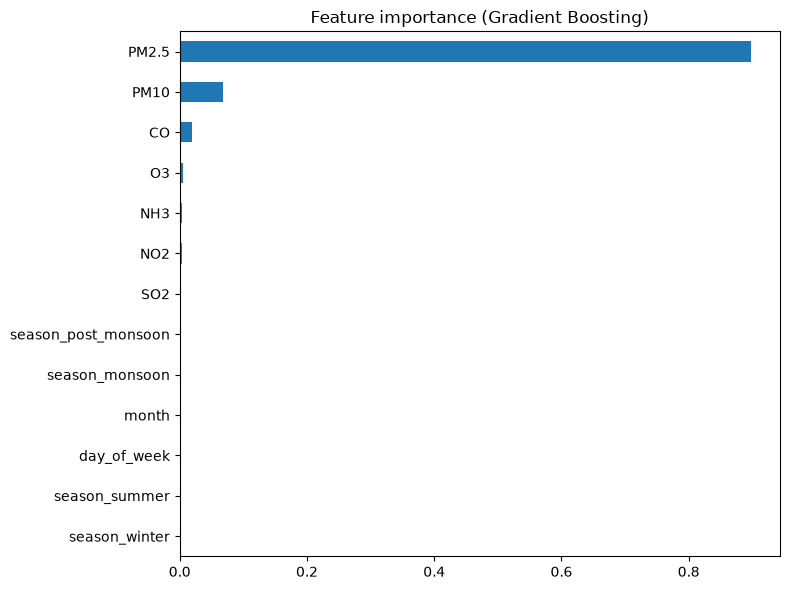

In [15]:
import matplotlib.pyplot as plt

importance = pd.Series(best.feature_importances_, index=feature_cols).sort_values()
importance.plot(kind="barh", figsize=(8, 6), title="Feature importance (Gradient Boosting)")
plt.tight_layout()
plt.show()

**Insight:** PM2.5 drives about 90% of the model's predictions, followed by PM10 and CO. Because the pollutant readings already carry the seasonal signal, month and season add little on their own. CO's importance should be read with care, since Ahmedabad's CO column was found to be copied from NO.

## 8. Conclusion

The best model, Gradient Boosting, forecasts tomorrow's AQI with an MAE of about 19 points on the 2019 to mid-2020 test period. That is roughly a 77% reduction compared with the baseline's MAE of 82.

PM2.5 is the main driver, and the largest errors occur in Ahmedabad, Guwahati and Gurugram, and in winter.

Limitations:
- Ahmedabad's CO column appears copied from NO, so its extreme AQI values were removed or capped, which affects that city.
- The test period includes the 2020 COVID lockdown, when pollution patterns changed.
- The model is saved on its own, without a full scikit-learn Pipeline, so the app must rebuild the features exactly.
- The models were compared on one test set. Cross-validation on the training data would be a stricter check.

Next steps: use a Pipeline, cross-validate, and add weather data (temperature, humidity, wind), which the dataset lacks.